# CNN (Task 1 - 2)

### Import Libraries

In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
import os

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

### Prepare Dataset

1. Load Dataset

In [2]:
# Train
print("Train Dataset:")
train_dataset = tf.keras.utils.image_dataset_from_directory(
    "seg_train/seg_train",
    image_size=(150, 150),
    validation_split=0.2,
    subset="training",
    seed=42
)

# Validate
print("\nValidate Dataset:")
validation_dataset = tf.keras.utils.image_dataset_from_directory(
    "seg_train/seg_train",
    image_size=(150,150),
    batch_size=32,
    validation_split=0.2,
    subset="validation",
    seed=42
)

print("\nTest Dataset:")
# Test
test_dataset = tf.keras.utils.image_dataset_from_directory(
    "seg_test/seg_test",
    image_size=(150, 150),
    batch_size=32,
    shuffle=False
)

class_names = train_dataset.class_names
num_classes = len(class_names)

Train Dataset:
Found 14034 files belonging to 6 classes.
Using 11228 files for training.

Validate Dataset:
Found 14034 files belonging to 6 classes.
Using 2806 files for validation.

Test Dataset:
Found 3000 files belonging to 6 classes.


2. Normalization

In [3]:
normalization_layer = tf.keras.layers.Rescaling(1./255)

def normalize_data(x, y):
    normalized_x = normalization_layer(x)
    return normalized_x, y



train_dataset = train_dataset.map(normalize_data)

validation_dataset = validation_dataset.map(normalize_data)

test_dataset = test_dataset.map(normalize_data)

3. Example Images

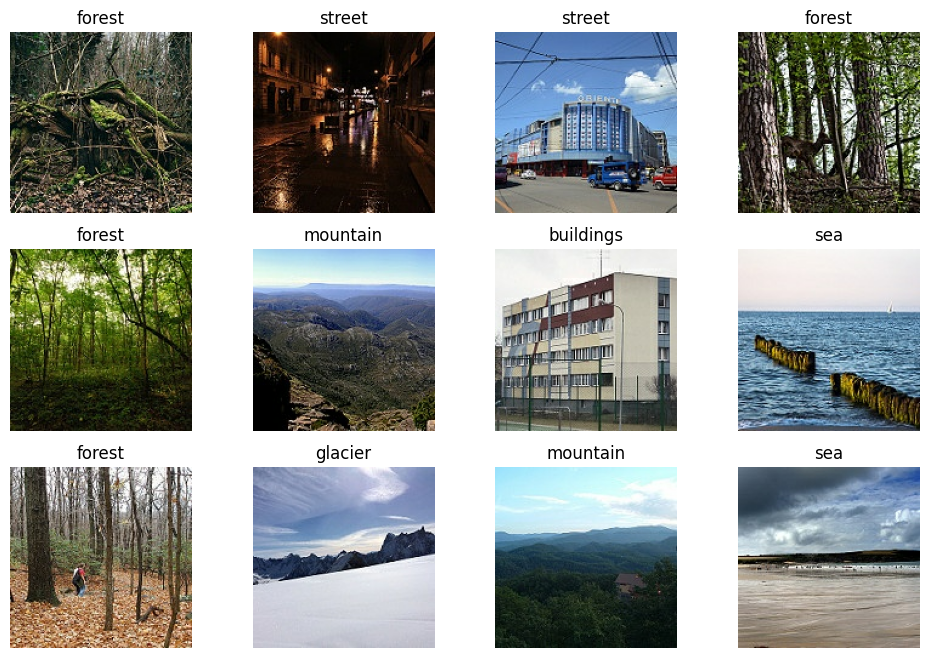

In [4]:
plt.figure(figsize=(12, 8))

for images, labels in train_dataset.take(1):
    for i in range(12):
        ax = plt.subplot(3, 4, i + 1)
        plt.imshow(images[i])
        plt.title(class_names[labels[i]])
        plt.axis("off")

plt.show()

### CNN model

1. Build a model

In [5]:
model = Sequential([
    Conv2D(32, (3, 3), activation="relu", input_shape=(150, 150, 3)),
    MaxPooling2D((2, 2)),
    
    Flatten(),
    
    Dense(128, activation="relu"),
    Dense(num_classes, activation="softmax")
])

c:\Users\Lenovo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


2. Compile and Train
- Use **Sparse Categorical Cross Entropy** if the labels look like 3,6,2,...
- Use **Categorical Cross Entropy** if the labels look like [0,1,0,...] [0,...,1,0]

In [6]:
# Compile
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Train
history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=10
)

Epoch 1/10


c:\Users\Lenovo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


351/351 ━━━━━━━━━━━━━━━━━━━━ 52s 144ms/step - accuracy: 0.6254 - loss: 1.6848 - val_accuracy: 0.7071 - val_loss: 0.8343
Epoch 2/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 45s 127ms/step - accuracy: 0.8193 - loss: 0.5208 - val_accuracy: 0.7359 - val_loss: 0.8228
Epoch 3/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 44s 125ms/step - accuracy: 0.9145 - loss: 0.2761 - val_accuracy: 0.7220 - val_loss: 0.9039
Epoch 4/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 44s 124ms/step - accuracy: 0.9638 - loss: 0.1400 - val_accuracy: 0.7167 - val_loss: 0.9990
Epoch 5/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 44s 125ms/step - accuracy: 0.9827 - loss: 0.0824 - val_accuracy: 0.7413 - val_loss: 0.9777
Epoch 6/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 44s 125ms/step - accuracy: 0.9879 - loss: 0.0622 - val_accuracy: 0.7242 - val_loss: 1.2684
Epoch 7/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 45s 127ms/step - accuracy: 0.9709 - loss: 0.1082 - val_accuracy: 0.7053 - val_loss: 1.2701
Epoch 8/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 45s 129ms/step - accuracy: 0.9841 - loss: 0.0613 - val

3. Evaluate

In [7]:
test_loss, test_accuracy = model.evaluate(test_dataset)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

94/94 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.7150 - loss: 1.4742
Test Accuracy: 71.50%


4. Save

In [9]:
model.save("CNN_Baseline.keras")